# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]        # TODO: list the column(s) that ColdSense derived (not measured by the freezer or written by technicians)
n_alerts = int((df.ai_flag == 1).sum())            # TODO: number of rows with an alert (ai_flag == 1)
fault_rate_pct = round(df.confirmed_fault.mean() * 100, 2)      # TODO: % of rows that are confirmed faults, 2 decimals (this is the base rate)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


fault_type
compressor trip         10
defrost heater stuck    11
sensor frozen           25
Name: fault hours, dtype: int64

**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:* `ai_score` is an ordered, quantitative attribute, so it should go on a magnitude channel: position on a common scale is best (e.g. a score axis or a ranked bar), with luminance/saturation or size as a secondary choice. `ai_flag` is binary (categorical), so an identity channel fits: a distinct hue or shape for flagged vs. not flagged. The flag throws away *how confident* the detector is: a 0.51 and a 0.99 look identical, and a 0.49 just below the cut looks the same as a 0.01. The score keeps that ranking, so we can see near-misses, borderline alerts and how the threshold choice changes things.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

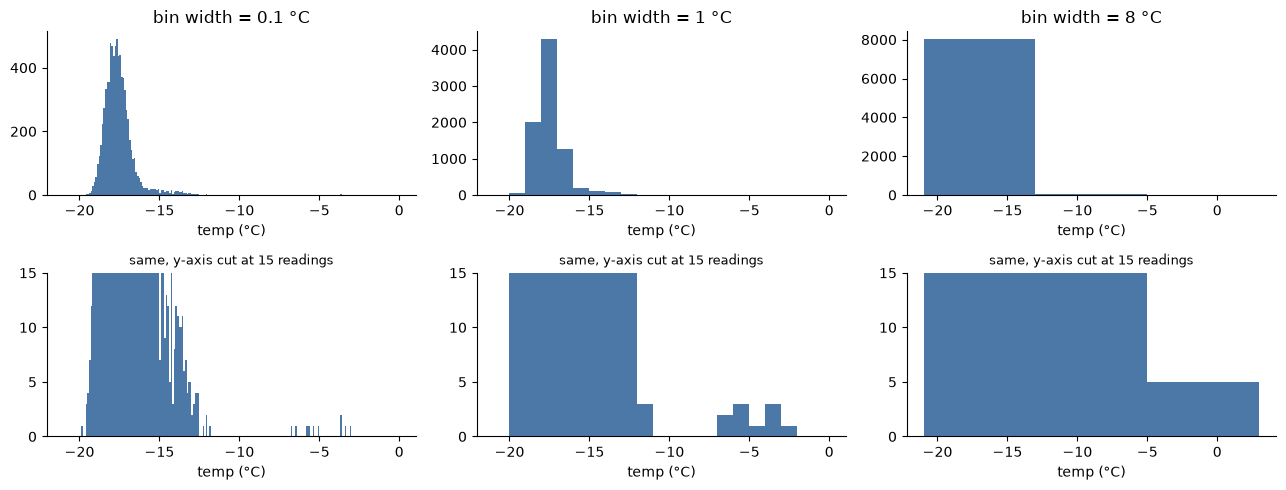

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]   # TODO: in the bottom row, which bin width(s) show the very warm readings (above -8 °C) as a separate group? a list, e.g. [0.1]
n_warm_readings = int((df.temp_c > -8).sum())          # TODO: how many readings are warmer than -8 °C? (count them with code)

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

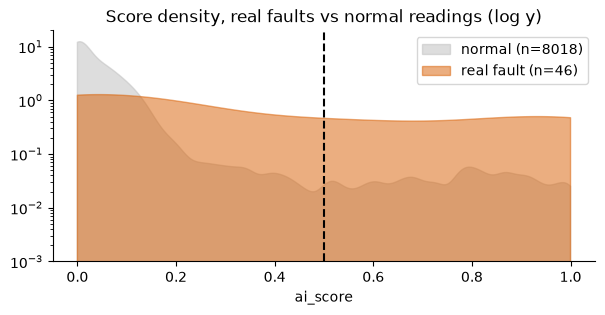

In [4]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False   # TODO: True/False - is there a clean score cut-off that separates real faults from normal readings?

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:* A histogram is not a neutral picture of the data: its shape depends on parameters we choose (bin width and bin origin, plus the y-axis range), and different settings give different pictures of the same readings. With 8 °C bins, the 10 very warm readings (above −8 °C) get merged into the same bin as the normal defrost readings, and with an uncut y-axis they are invisible next to the ~8,000 normal readings. So "the 8 °C histogram shows no anomalies" only means *that setting* hid them. I'd tell my colleague to try narrower bins (1 °C or 0.1 °C) and to zoom the y-axis: then the warm tail shows up as a separate group. Also, the score density plot shows the real faults and normal readings overlap a lot, so no single cut-off separates them cleanly.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = np.max(np.abs((v - v.mean()) / np.std(v, ddof=1)))          # TODO: the largest |z| in v, using the sample SD (hint: np.std(v, ddof=1))
q1, q3 = np.percentile(v, [25, 75])
upper_fence = q3 + 1.5 * (q3 - q1)    # TODO: Q3 + 1.5 * IQR

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:* The −3.6 °C trip reading pulls the mean up and inflates the standard deviation so much that its own z-score is only about 2.83; this is *masking*, and with n = 10 the largest possible |z| is (n−1)/√n ≈ 2.85, so a |z| > 3 rule can never fire on this window at all. The IQR rule uses quartiles, which barely move when one extreme value is added, so the upper fence stays near −15.6 °C and the trip is clearly beyond it.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())    # TODO: alerts that were real faults
FP = int((flag & ~real).sum())    # TODO: alerts on normal readings (false alarms)
FN = int((~flag & real).sum())    # TODO: real faults with no alert (missed)
TN = int((~flag & ~real).sum())    # TODO: normal readings with no alert

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
precision = TP / (TP + FP)              # TODO
recall = TP / (TP + FN)                 # TODO
f1 = 2 * precision * recall / (precision + recall)                     # TODO
accuracy = (TP + TN) / len(df)               # TODO
flag_nothing_accuracy = (FP + TN) / len(df)  # TODO: accuracy of a "detector" that never raises an alert

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 99.4%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:* "ColdSense's 97.9% accuracy is lower than a detector that never raises an alert (99.4%), because only 0.57% of hours are real faults. Its *precision is 0.10*: of 159 alerts, only 16 were real faults, so about *9 out of every 10 call-outs are wasted* (143 false alarms). Its *recall is 0.35*: it caught 16 of 46 fault hours and *missed 30 (about 2 in 3)*. The alerts are useful as candidates to check, not as instructions to dispatch a technician." 

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

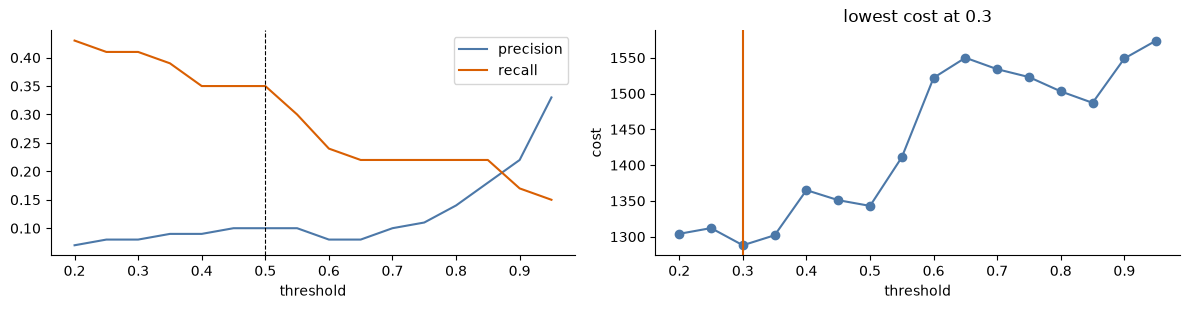

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep.FN + 1 * sweep.FP          # TODO: 40 * FN + 1 * FP
best_threshold = sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"]         # TODO: the threshold with the lowest cost (hint: sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"])

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:* The lowest cost is at threshold 0.30, not the default 0.5 (cost 1288 vs 1343), but recall still only reaches about 0.41. That's because the "sensor frozen" faults (25 of the 46 fault hours) get scores of almost zero (max ≈ 0.10): a stuck sensor reports a perfectly normal-looking −18 °C, so each reading on its own looks fine. Since these faults sit at the very bottom of the score range together with normal readings, moving the threshold can't catch them without flagging nearly everything. The problem is what the model looks at (single points, no context or sequence), not where the line is drawn.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

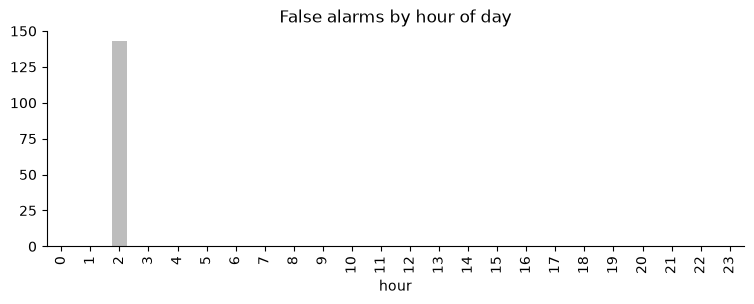

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_peak_hour = int(fp_rows.groupby("hour").size().idxmax())          # TODO: the hour with the most false alarms (an int)
fp_share_at_peak = (fp_rows.hour == fp_peak_hour).mean()      # TODO: share of all false alarms that fall in that hour (0-1)

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = caught["recall"].idxmin()   # "sensor frozen"     # TODO: the fault type ColdSense never catches
anomaly_kind = "collective"          # TODO: is that a 'point', 'contextual' or 'collective' anomaly?

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"]       # TODO: (temp_c - hour_median) / hour_mad

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


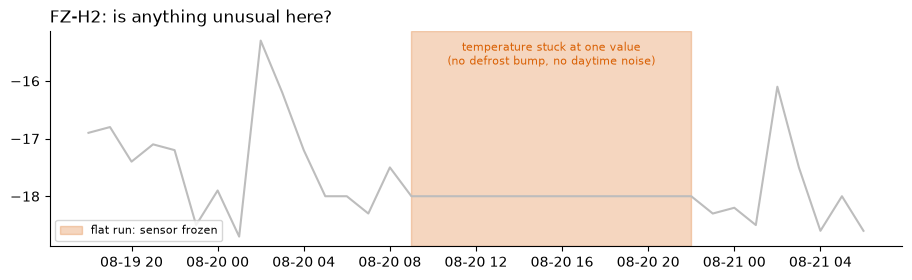

In [12]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]   # TODO: rows where the 6-hour rolling SD is (almost) zero, e.g. df[df["roll_sd_6h"] < 0.01]

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    # TODO (drawing): highlight the WHOLE flat span on this chart, not single points (hint: ax.axvspan(start, end, color=ACCENT, alpha=.25))
    h2_flat = flat[flat.freezer_id == "FZ-H2"]
    start, end = h2_flat.timestamp.min() - pd.Timedelta(hours=5), h2_flat.timestamp.max()
    ax.axvspan(start, end, color=ACCENT, alpha=.25, label="flat run: sensor frozen")
    ax.annotate("temperature stuck at one value\n(no defrost bump, no daytime noise)", xy=(start + (end - start) / 2, h2.temp_c.max()),
                ha="center", va="top", fontsize=8, color=ACCENT)
    ax.legend(loc="lower left", fontsize=8)
    
    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*

(a) Corrected: "Most *false alarms* happen at 2 am (100% of the 143 false alarms fall in the 02:00 hour); *no confirmed faults* happened at 2 am. These alerts are the scheduled 02:00–04:00 defrost cycle, which ColdSense does not know about." The real faults happen mostly in the afternoon (13:00–17:00). A night technician would spend every night chasing normal defrost warm-ups, while the actual faults happen during the day when nobody extra is watching.

(b) Not as stated. −14 °C is normal at 02:00–03:00 (defrost) but abnormal at 14:00; the "defrost heater stuck" faults are exactly that: −14 °C in the afternoon. That makes it a *contextual anomaly*: whether a value is abnormal depends on its context (here, hour of day and the freezer's own pattern). The context-aware baseline (same freezer, same hour) catches daytime faults ColdSense missed and raises zero false alarms at 02:00. To judge such an alert, a chart must show the reading *against its expected value for that context*, e.g. the freezer's typical band for that hour (median ± MAD) drawn behind the line, with the defrost window shaded, so the viewer can see the reading is unusual *for that time*.

(c) Statement 4 is false: the maintenance log shows FZ-H2 had a *frozen sensor for 14 hours on 20 Aug* (09:00–22:00), and ColdSense scored all of those hours near 0. A frozen sensor reports a plausible −18 °C, so every single reading looks normal; what is abnormal is the *run*: no variation, no defrost bump, no door-opening noise. This is a *collective anomaly*, and a detector that scores each reading independently never looks at the sequence, so it can't see it. You need a feature over a window (e.g. rolling SD ≈ 0) and a chart that highlights the whole span.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

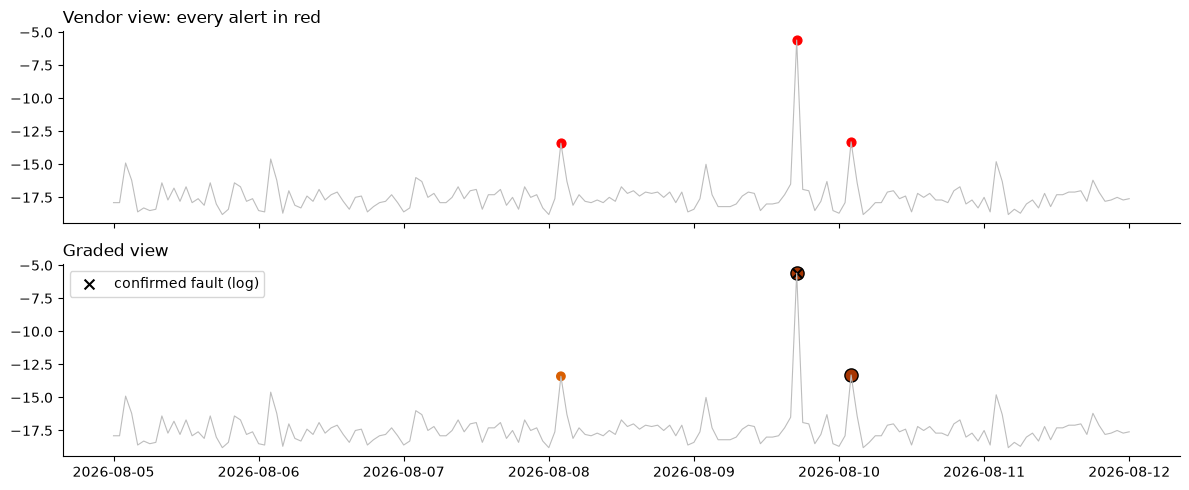

In [13]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    # TODO: replace the single return below with the four bands
    if score >= 0.90:
        return ("#a63603", 90, "black")    
    if score >= 0.70:
        return (ACCENT, 50, "none")        
    if score >= 0.50:
        return ("white", 35, ACCENT)       
    return (GREY, 8, "none") 

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

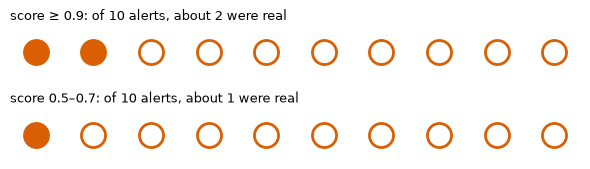

In [14]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = int(round(band_hi.confirmed_fault.mean() * 10))   # TODO: of 10 alerts with score >= 0.9, about how many were real faults? (round to a whole number)
real_per_10_lo = int(round(band_lo.confirmed_fault.mean() * 10))   # TODO: same for scores 0.5-0.7

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*

(a) Red dots have very high *salience*, so they grab attention first and the team's eyes jump from dot to dot. Every night there are new red dots at 02:00, so attention is spent on those, and anything with *no* dot fades into the background. The frozen H2 sensor gets no dot at all (scores ≈ 0) and looks like a calm flat line, so it is a classic case of *inattentional blindness*: people focused on the highlighted items fail to notice an unexpected pattern that is plainly visible. Painting all alerts the same red also hides that most of them are low-confidence, which trains the team to tune the whole dashboard out.

(b) "Of every 10 alerts with a score of 0.9 or higher, about *2* turned out to be real faults (8 of 37). For scores between 0.5 and 0.7, about *1 in 10* was real (6 of 55). A score of 0.92 is a ranking, not a 92% probability: higher scores are more likely to be real, but most alerts at every level are still false alarms." 

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)        # TODO: standard error of the baseline mean
z_sd = (new_reading - mu) / sd      # TODO: (new_reading - mu) / sd
z_se = (new_reading - mu) / se      # TODO: (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = "SD"   # TODO: 'SD' or 'SE' - which one should be used to judge a single new reading?

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:* The SD (≈ 0.61 °C) describes how much *individual readings* of FZ-B1 at 14:00 spread around their average, so it is the right yardstick for judging one new reading. The SE (≈ 0.09 °C) describes how precisely we know the *mean* of the 42 baseline readings, so it shrinks with n and is far too small for comparing a single reading. Rewritten: "A new FZ-B1 reading of −15.9 °C at 14:00 is about 2.3 standard deviations above this freezer's normal 14:00 level (−17.3 °C). That is unusual and worth a check (look at the following hours and door openings), but it is not a definite fault." 

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {
    1: "Correct",   # 97.9% accurate, so trustworthy
    2: "Reject",   # most faults happen around 2 am
    3: "Accept",   # all 10 compressor trips caught
    4: "Reject",   # FZ-H2 had no fault
    5: "Correct",   # -14 °C is abnormal at any time
    6: "Correct",   # score 0.92 = 92% chance
    7: "Correct",   # threshold 0.5 is best
    8: "Correct",   # 15 standard errors: definite fault
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Correct    5
Reject     2
Accept     1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:* 

```
┌──────────────────────────── Freezer FZ-xx · last 48 h ─────────────────────────────┐
│ MAIN VIEW: temp line (grey) + expected band for each hour (median ± MAD)           │
│            defrost 02:00–04:00 shaded · alerts graded by score (hollow → solid)    │
│            flat-sensor runs highlighted as a whole span                            │
├──────────────── CONTEXT ─────────────────┬────────── ALERT QUEUE ──────────────────┤
│ small multiples: same hour, other days;  │ sorted by expected cost (score × stock) │
│ door_opens + compressor_kw strips below  │ type tag: point / contextual / flat-run │
│ the temp line                            │ "about 2 in 10 like this were real"     │
├──────────────── VERIFICATION ────────────┼────────── EVALUATION ───────────────────┤
│ click alert → raw readings, z vs own-hour│ running precision & recall by week,     │
│ baseline (SD, not SE), similar past cases│ confusion matrix, threshold slider with │
│ buttons: confirmed / false alarm / unsure│ cost curve (40:1), recall per fault type│
└──────────────────────────────────────────┴─────────────────────────────────────────┘
```

- Main view: the temperature time series with a context-aware expected band, the defrost window shaded, and emphasis scaled to the score (no red-for-everything).
- Context: door openings and compressor power aligned under the temperature line, plus the same hour on previous days, so a viewer can tell a defrost bump from a stuck heater.
- Queue: a ranked list of candidates (point, contextual and flat-run alerts together), with frequency-framed confidence.
- Verification tools: drill-down to raw readings, the per-hour baseline in SD units, and confirm / false-alarm buttons that feed back into the maintenance log.
- Evaluation: live precision, recall per fault type and a threshold slider with the cost curve, so the threshold is a visible business decision.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:* Statement 1 felt the most convincing at first, mainly because of the number: "97.9%" sounds precise and scientific, so I didn't question it. Only after computing the never-alert baseline (99.4%) did I see how empty it was. Without the maintenance log I would have caught some issues, like the 2 am pattern lining up with the defrost schedule, but I could not have measured precision and recall, and I would have completely missed the frozen H2 sensor because it looked like a perfectly normal line.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:* The threshold is a business trade-off, not a technical default, so it should be owned by the cold-chain lead (Ravi) together with operations/finance, who know the real cost of spoiled stock versus a technician's time. The vendor shouldn't set it. The dashboard should show a threshold slider with the resulting precision, recall, expected call-outs per week and missed faults, plus the cost curve under the agreed cost ratio (here 40:1), so the owner can see what each choice actually means.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:* Labels would only exist where someone was sent to check, which is mostly where ColdSense raised an alert. Missed faults (like the frozen sensor) would never be recorded, so recall would look much higher than it really is, and precision could be off too, since some unconfirmed alerts may have been real. The workflow can reduce this by randomly spot-checking a small sample of *unflagged* freezer-hours, by asking technicians to record every visit outcome (confirmed / false alarm / unsure), and by cross-checking with independent signals like stock spoilage reports and compressor power.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:* For every alert, show the reading next to its own context (the expected band for that freezer and hour, with the defrost window shaded) and the frequency line "about 2 in 10 alerts like this were real", and require a one-click verdict (confirmed / false alarm / unsure) before the alert can be closed. Seeing the evidence and the honest hit rate makes them look before acting, and the verdict step turns each check into new ground truth.